# Por qué se eliminó el AMA, el debate sobre el SMA y la inestabilidad de colas pesadas

**Pregunta:** ¿Sigue una fórmula estandarizada que ignora la cola el riesgo de un banco cuya distribución de pérdidas verdadera se conoce, y es el modelo interno que reemplazó lo bastante estable con diez años de datos como para haber valido la pena conservarlo?


- **Nivel:** 3, comparación con métodos publicados
- **Requisitos previos:** los notebooks 02 a 06 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este notebook puedes:

- explicar por qué el Comité de Basilea eliminó el Enfoque de Medición Avanzada (AMA) y lo reemplazó por el Enfoque de Medición Estándar (SMA), y qué argumentó la crítica académica al SMA;
- poner los dos enfoques lado a lado sobre las mismas historias versionadas de un banco sintético, para cuatro índices de cola y dos umbrales de recolección;
- leer, en números, las afirmaciones de que el SMA es insensible al perfil de riesgo y de que una distribución de pérdidas estimada cerca de un índice de cola de 1 es inestable;
- decir qué dicen y qué no dicen estos resultados sintéticos sobre bancos reales.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. El generador del caso C17 y sus estimadores viven en `data-pipeline/pipeline/cases/c17/`, que no es un paquete instalado: este notebook carga esos módulos por su ruta (importar todo el paquete `data-pipeline` importaría todos los casos y sus dependencias pesadas). La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
import types
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.oprisk import distributions, sma
from riskvalidation.validation import oprisk as oprisk_tests

for name in ('riskvalidation', 'numpy', 'scipy', 'matplotlib'):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son las cuatro variantes del caso C17, una por índice de cola del banco sintético (0,6, 0,8, 0,96 y 1,1), cada una con 16 números para comparar: cuatro celdas (5 o 10 años de datos, umbral de recolección EUR 10.000 o 20.000) de 1.000 historias simuladas independientes, estimadas por la escalera LDA y por el SMA, frente a un cuantil anual de 99,9% verdadero y conocido.

- **Archivos que se leen:** `data/derived/C17/xi-0-6.json`, `xi-0-8.json`, `xi-0-96.json` y `xi-1-1.json`: `outputs.truth`, `outputs.cells[*].capital.lda_splice`, `outputs.cells[*].sma`, `outputs.bank` y `outputs.sma_response`, e `impact`.
- **Por qué el empalme:** entre los peldaños LDA, los lognormales son estables y muy sesgados (notebook 06), y los de aproximación y de escenarios son variantes del modelo de cola. El cuerpo lognormal con cola Pareto generalizada es el peldaño que defendería un modelador de riesgo operacional, y por eso es el que se contrasta con el SMA.
- **Qué es sintético:** el generador se calibra a medianas publicadas pero inventa el banco y sus pérdidas. Nada de lo que sigue mide un banco real.

La celda siguiente carga los documentos y el generador.

In [2]:
# Cargar los cuatro documentos de las variantes y el generador del caso por ruta
ROOT = Path("../../..").resolve()
docs = {
    name: json.loads(
        (ROOT / "data" / "derived" / "C17" / (name + ".json")).read_text(encoding="utf-8")
    ) for name in ("xi-0-6", "xi-0-8", "xi-0-96", "xi-1-1")
}
sys.dont_write_bytecode = True
paquete_caso = types.ModuleType("c17")
paquete_caso.__path__ = [str(ROOT / "data-pipeline" / "pipeline" / "cases" / "c17")]
sys.modules["c17"] = paquete_caso
from c17 import generator, replicate

for name, doc in docs.items():
    print(
        name, "| cuantil de 99.9% verdadero de la pérdida anual (EUR):",
        format(doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"], ",.0f"),
        "| calculado por riskvalidation", doc["provenance"]["riskvalidation_version"]
    )

xi-0-6 | cuantil de 99.9% verdadero de la pérdida anual (EUR): 33,897,000 | calculado por riskvalidation 1.0.1
xi-0-8 | cuantil de 99.9% verdadero de la pérdida anual (EUR): 163,483,000 | calculado por riskvalidation 1.0.1
xi-0-96 | cuantil de 99.9% verdadero de la pérdida anual (EUR): 634,865,452 | calculado por riskvalidation 1.0.1
xi-1-1 | cuantil de 99.9% verdadero de la pérdida anual (EUR): 2,148,602,460 | calculado por riskvalidation 1.0.1


## Método

### Paso 1: ambos enfoques sobre las mismas historias

Para cada variante y celda el documento guarda, sobre las 1.000 historias, la razón del capital del empalme LDA con el cuantil verdadero (su mediana, su rango intercuartil sobre la verdad y la proporción de historias donde el peldaño está definido) y la razón del capital del SMA (el capital por riesgo operacional, ORC, del notebook 05) con el mismo cuantil verdadero. La celda siguiente imprime las 16 filas. El SMA se calcula en toda historia, así que siempre está definido; el empalme está definido solo donde converge su ajuste.

In [3]:
# Ambos enfoques contra el cuantil verdadero, en las 16 celdas de las cuatro variantes
print(
    "%-8s %-10s | %-34s | %-30s" % (
        "", "", "LDA empalme: definido, mediana, RIC / verdad", "SMA: mediana, p25 - p75 sobre la verdad"
    )
)
for name, doc in docs.items():
    for cell in doc["outputs"]["cells"]:
        splice = cell["capital"]["lda_splice"]
        ratio = cell["sma"]["orc_over_true_quantile"]
        print(
            "%-8s %-10s | %4d  %6.3f  %6.3f              | %6.3f   %6.3f - %6.3f" % (
                name, cell["id"], splice["n_defined"], splice["ratio_to_truth"]["median"], splice["iqr_over_truth"],
                ratio["median"], ratio["p25"], ratio["p75"]
            )
        )

                    | LDA empalme: definido, mediana, RIC / verdad | SMA: mediana, p25 - p75 sobre la verdad
xi-0-6   y5-h10000  |  959   0.764   1.952              |  4.022    3.941 -  4.120
xi-0-6   y5-h20000  |  771   0.764   2.033              |  3.967    3.890 -  4.073
xi-0-6   y10-h10000 |  996   0.850   1.429              |  4.030    3.967 -  4.111
xi-0-6   y10-h20000 |  859   0.840   1.354              |  3.975    3.906 -  4.053
xi-0-8   y5-h10000  |  904   0.663   2.744              |  0.873    0.846 -  0.921
xi-0-8   y5-h20000  |  682   0.639   2.560              |  0.859    0.829 -  0.901
xi-0-8   y10-h10000 |  971   0.816   1.776              |  0.882    0.857 -  0.915
xi-0-8   y10-h20000 |  727   0.909   1.983              |  0.869    0.843 -  0.908
xi-0-96  y5-h10000  |  725   0.781   3.104              |  0.239    0.227 -  0.258
xi-0-96  y5-h20000  |  550   0.627   3.299              |  0.233    0.221 -  0.254
xi-0-96  y10-h10000 |  818   0.764   2.111              |  0.

### Paso 2: el SMA en el motor, sobre una historia por variante

El ORC del SMA depende de la historia solo a través de la pérdida anual promedio, y del banco solo a través de su indicador de negocio. Regeneramos la historia detrás de cada bloque de respuesta versionado y llamamos a `sma_capital` con el indicador de negocio del banco; la mediana versionada sobre 1.000 historias de la celda con 10 años y umbral de EUR 20.000 se imprime a su lado. El indicador de negocio del banco es el mismo en las cuatro variantes, así que toda diferencia del capital del SMA entre variantes viene solo de las pérdidas.

In [4]:
# El capital SMA de una historia regenerada por variante, junto a la mediana versionada de la celda
print("%-8s %16s %12s %12s | %16s" % ("", "pérdida anual promedio", "ILM", "ORC", "ORC mediano versionado"))
orc_single = {}
for name, doc in docs.items():
    block = doc["outputs"]["sma_response"]
    history = generator.draw_history(
        generator.variant(doc["outputs"]["tail_index"]), block["seed"], 10
    ).recorded(20_000.0)
    result = sma.sma_capital(doc["outputs"]["bank"]["business_indicator"]["bi_eur"], history.annual)
    orc_single[name] = result.orc
    cell = next(c for c in doc["outputs"]["cells"] if c["id"] == "y10-h20000")
    print(
        "%-8s %16s %12.4f %12s | %16s" % (
            name, format(history.annual.mean(), ",.0f"), result.ilm, format(result.orc, ",.0f"),
            format(cell["sma"]["orc_eur"]["median"], ",.0f")
        )
    )

         pérdida anual promedio          ILM          ORC | ORC mediano versionado
xi-0-6          3,442,129       0.7355  132,388,684 |      134,743,278
xi-0-8          5,005,391       0.7953  143,154,295 |      142,003,392
xi-0-96         6,759,268       0.8544  153,800,481 |      151,571,436
xi-1-1          5,016,737       0.7957  143,227,478 |      165,036,744


La SMA lee la historia solo por su promedio. El estimador del caso, `replicate.estimate`, ajusta además el enfoque de distribución de pérdidas sobre la misma historia, así que la siguiente celda pone los dos capitales de la historia regenerada de cada variante junto al cuantil verdadero.

In [5]:
# El capital de la SMA y del empalme LDA de la misma historia regenerada de cada variante, sobre el cuantil verdadero
for name, doc in docs.items():
    block = doc["outputs"]["sma_response"]
    variant_k = generator.variant(doc["outputs"]["tail_index"])
    bi_k = doc["outputs"]["bank"]["business_indicator"]["bi_eur"]
    history = generator.draw_history(variant_k, block["seed"], 10).recorded(20_000.0)
    try:
        fit = distributions.fit_splice(history.amounts, 20_000.0, 100_000.0)
        fit_text = "convergió %s, peso del cuerpo %.3f, índice de cola %.3f" % (
            fit.converged, fit.params[5], fit.params[3]
        )
    except ValueError as error:
        fit_text = "rechazado: %s" % str(error)[:40]
    one = replicate.estimate(variant_k, block["seed"], 10, 20_000.0, bi_k, None, 20_000)
    truth_q = doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
    splice = one["lda_splice"]
    splice_text = "no definido" if np.isnan(splice) else "%s (%.3f de la verdad)" % (
        format(splice, ",.0f"), splice / truth_q
    )
    print("%-8s verdad %15s | SMA %15s (%.3f de la verdad) | empalme LDA %s" %
          (name, format(truth_q, ",.0f"), format(one["orc"], ",.0f"), one["orc"] / truth_q, splice_text))
    print("%-8s ajuste del empalme a la historia: %s" % ("", fit_text))

xi-0-6   verdad      33,897,000 | SMA     132,388,684 (3.906 de la verdad) | empalme LDA 16,463,868 (0.486 de la verdad)
         ajuste del empalme a la historia: convergió True, peso del cuerpo 0.937, índice de cola 0.472
xi-0-8   verdad     163,483,000 | SMA     143,154,295 (0.876 de la verdad) | empalme LDA no definido
         ajuste del empalme a la historia: convergió False, peso del cuerpo 1.000, índice de cola 0.686
xi-0-96  verdad     634,865,452 | SMA     153,800,481 (0.242 de la verdad) | empalme LDA no definido
         ajuste del empalme a la historia: convergió False, peso del cuerpo 1.000, índice de cola 1.029
xi-1-1   verdad   2,148,602,460 | SMA     143,227,478 (0.067 de la verdad) | empalme LDA 953,379,755 (0.444 de la verdad)
         ajuste del empalme a la historia: convergió True, peso del cuerpo 0.994, índice de cola 1.036


### Paso 3: cuánto se mueve el capital cuando se mueve el perfil de riesgo

Entre las cuatro variantes el cuantil de 99,9% verdadero de la pérdida anual se multiplica por un factor grande, porque el índice de cola va de 0,6 a 1,1 con una frecuencia parecida. Una medida que siga al riesgo debería seguirlo. La celda siguiente imprime, para la celda con 10 años y umbral de EUR 20.000, el cuantil verdadero, el capital mediano del SMA y el capital mediano del empalme LDA, y el factor entre el mayor y el menor de cada uno.

In [6]:
# Cuantil verdadero, capital SMA mediano y capital mediano del empalme LDA en las cuatro variantes (10 años, umbral
# EUR 20.000)
rows = []
for name, doc in docs.items():
    cell = next(c for c in doc["outputs"]["cells"] if c["id"] == "y10-h20000")
    truth_q = doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
    rows.append(
        (name, truth_q, cell["sma"]["orc_eur"]["median"], cell["capital"]["lda_splice"]["capital_eur"]["median"])
    )
    print(
        "%-8s verdad %15s | SMA %15s | LDA empalme %15s" % (
            name, format(truth_q, ",.0f"), format(rows[-1][2], ",.0f"), format(rows[-1][3], ",.0f")
        )
    )
for label, column in (("cuantil verdadero", 1), ("SMA", 2), ("LDA empalme", 3)):
    values = [r[column] for r in rows]
    print("%-24s mayor / menor: %.1f" % (label, max(values) / min(values)))

xi-0-6   verdad      33,897,000 | SMA     134,743,278 | LDA empalme      28,481,721
xi-0-8   verdad     163,483,000 | SMA     142,003,392 | LDA empalme     148,533,735
xi-0-96  verdad     634,865,452 | SMA     151,571,436 | LDA empalme     589,526,564
xi-1-1   verdad   2,148,602,460 | SMA     165,036,744 | LDA empalme   1,558,118,060
cuantil verdadero        mayor / menor: 63.4
SMA                      mayor / menor: 1.2
LDA empalme              mayor / menor: 54.7


La siguiente celda dibuja el capital de cada enfoque a través de los cuatro índices de cola, en un eje logarítmico: el cuantil de 99,9% verdadero, el capital mediano de la SMA y el capital mediano del empalme LDA, de la tabla impresa arriba.

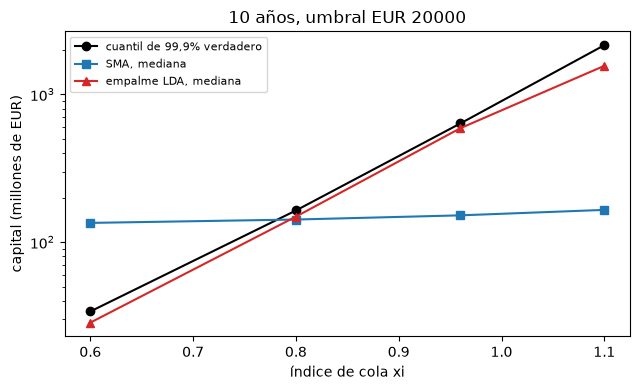

In [7]:
# Dibujar el cuantil verdadero, el capital mediano de la SMA y el del empalme LDA a través de los índices de cola
xis = [doc["outputs"]["tail_index"] for doc in docs.values()]
fig, ax = plt.subplots(figsize=(6.5, 4.0))
ax.semilogy(xis, [r[1] / 1e6 for r in rows], "ko-", label="cuantil de 99,9% verdadero")
ax.semilogy(xis, [r[2] / 1e6 for r in rows], "s-", color="tab:blue", label="SMA, mediana")
ax.semilogy(xis, [r[3] / 1e6 for r in rows], "^-", color="tab:red", label="empalme LDA, mediana")
ax.set_xlabel("índice de cola xi")
ax.set_ylabel("capital (millones de EUR)")
ax.set_title("10 años, umbral EUR 20000")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La línea negra es el riesgo: sube de EUR 33.897.000 con índice de cola 0,6 a EUR 2.148.602.460 con 1,1, un factor de 63,4. La línea roja lo sigue, un factor de 54,7, mientras la línea azul de la SMA es casi plana, de EUR 134.743.278 a EUR 165.036.744, un factor de 1,2. Un banco cuya cola se vuelve mucho más pesada no ve cambio en su capital estandarizado; esa es la insensibilidad al riesgo que describen los críticos. La figura muestra solo medianas y nada dice de la dispersión de la línea roja, que dibuja la figura posterior.

### Paso 4: el índice de cola ajustado sobre una historia cerca de 1

El LDA necesita el índice de cola, y cerca de 1 es difícil de aprender. Sobre la historia de cada variante ajustamos la Pareto generalizada en los cuatro umbrales del notebook 02 con `tail_index_profile` e imprimimos las estimaciones y sus errores estándar. El índice verdadero de la última variante, 1,1, significa media infinita; que el ajustado quede sobre o bajo 1 depende de la muestra.

In [8]:
# Ajustar el perfil del índice de cola sobre la historia regenerada de cada variante
thresholds = 20_000.0 * np.array([1.0, 2.0, 4.0, 8.0])
profiles = {}
for name, doc in docs.items():
    block = doc["outputs"]["sma_response"]
    history = generator.draw_history(
        generator.variant(doc["outputs"]["tail_index"]), block["seed"], 10
    ).recorded(20_000.0)
    profiles[name] = distributions.tail_index_profile(history.amounts, thresholds)
    xi_hat, xi_se = profiles[name].xi, profiles[name].xi_se
    print("%-8s xi verdadero %-5s | xi_hat %s | ee %s | estimaciones en 1 o más: %d" %
          (name, doc["outputs"]["tail_index"], np.round(xi_hat, 3), np.round(xi_se, 3), int((xi_hat >= 1).sum())))

xi-0-6   xi verdadero 0.6   | xi_hat [0.588 0.468 0.501 0.378] | ee [0.081 0.099 0.154 0.178] | estimaciones en 1 o más: 0
xi-0-8   xi verdadero 0.8   | xi_hat [0.936 0.845 0.745 0.681] | ee [0.093 0.124 0.166 0.239] | estimaciones en 1 o más: 0
xi-0-96  xi verdadero 0.96  | xi_hat [1.02  0.963 1.029 0.87 ] | ee [0.099 0.129 0.198 0.257] | estimaciones en 1 o más: 2
xi-1-1   xi verdadero 1.1   | xi_hat [0.956 0.947 1.04  0.89 ] | ee [0.095 0.135 0.211 0.328] | estimaciones en 1 o más: 1


La siguiente celda dibuja esos índices ajustados con barras de dos errores estándar frente al valor verdadero de cada variante y la línea en 1, donde la media de la severidad deja de ser finita.

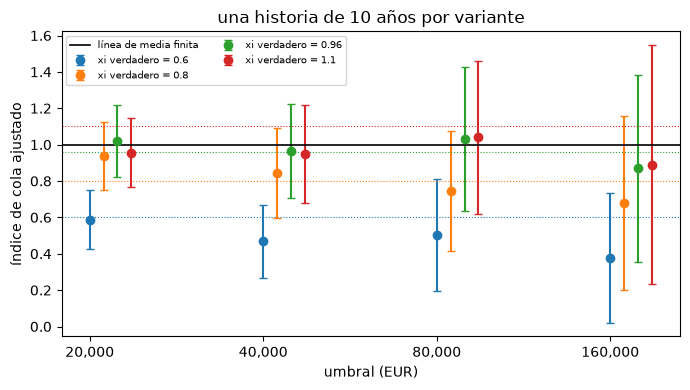

In [9]:
# Dibujar los índices de cola ajustados de una historia por variante frente al índice verdadero y la línea de media
# finita
palette = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
fig, ax = plt.subplots(figsize=(7.0, 4.0))
for k, (name, doc) in enumerate(docs.items()):
    true_xi = doc["outputs"]["tail_index"]
    fit = profiles[name]
    ax.errorbar(
        np.arange(4) + 0.08 * k, fit.xi, yerr=2 * fit.xi_se, fmt="o", color=palette[k], capsize=3,
        label="xi verdadero = %s" % true_xi
    )
    ax.axhline(true_xi, color=palette[k], linestyle=":", linewidth=0.8)
ax.axhline(1.0, color="black", linewidth=1.2, label="línea de media finita")
ax.set_xticks(range(4))
ax.set_xticklabels([format(int(u), ",") for u in thresholds])
ax.set_xlabel("umbral (EUR)")
ax.set_ylabel("índice de cola ajustado")
ax.set_title("una historia de 10 años por variante")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

Las dos variantes pesadas son el problema: con un índice verdadero de 0,96 dos de los cuatro valores ajustados quedan en la línea negra o sobre ella, y con un 1,1 verdadero solo uno, con los otros tres en 0,956, 0,947 y 0,89 diciendo al modelador que la media es finita cuando no lo es. Las barras son anchas, de 0,095 a 0,328 en error estándar, así que los datos no distinguen 0,96 de 1,1. Este es el mecanismo detrás de la inestabilidad de la figura siguiente. Usa una historia por variante; otras historias cruzarían la línea en otros lugares.

## Comparación

**Por qué se eliminó el AMA.** En su documento consultivo del 4 de marzo de 2016 el Comité de Basilea escribió que su revisión de las prácticas de modelación del riesgo operacional de los bancos y de los resultados de capital había revelado que la complejidad inherente del Enfoque de Medición Avanzada (AMA), y la falta de comparabilidad que surge de una amplia gama de prácticas internas de modelación, habían exacerbado la variabilidad de los cálculos de activos ponderados por riesgo y erosionado la confianza en los coeficientes de capital ponderados por riesgo. Propuso eliminar el AMA y basar el marco en un único método no basado en modelos, el Enfoque de Medición Estándar (BCBS, 2016). Las reformas finales están en Basilea III: Finalizando las reformas posteriores a la crisis (BCBS, 2017), y las reglas del enfoque estándar son el capítulo OPE25 del Marco de Basilea usado en el notebook 05.

**La crítica.** Peters, Shevchenko, Hassani y Chapelle (2016) discuten lo que llaman las debilidades y trampas del SMA, entre ellas la inestabilidad, la insensibilidad al riesgo y la superaditividad, y proponen mantener el marco de modelos internos AMA con recomendaciones de estandarización. Mignola, Ugoccioni y Cope (2016) publicaron comentarios a la propuesta del Comité en el mismo número de la revista.

**Qué es el enfoque de distribución de pérdidas (LDA).** La suma compuesta del notebook 01 con los bloques del notebook 02 (Chavez-Demoulin, Embrechts y Neslehova, 2006), calculada de forma exacta con la recursión de Panjer (1981) o la transformada rápida de Fourier y verificada frente a Shevchenko (2010) en el notebook 03, aproximada en forma cerrada en el notebook 04, y combinada con escenarios de expertos por credibilidad bayesiana en el notebook 05 (Shevchenko y Wuthrich, 2006). Para la aproximación de forma cerrada, la investigación detrás de este caso resume a Degen (2010) como un análisis por índice de cola que halla una zona problemática cerca de un índice de cola de 1; el texto primario no se volvió a leer para este notebook.

**Donde la investigación lee más de lo que dicen las fuentes.** La investigación detrás del caso presenta la inestabilidad de colas pesadas como un caso didáctico, construido sobre una calibración ilustrativa de las medianas de 2008 del Comité de Basilea (un índice de cola cercano a 0,96, con salvedades), y la lee como el tipo de inestabilidad que motivó el abandono del AMA. Esa lectura es de la propia investigación: el documento del Comité da la complejidad y la comparabilidad como sus razones. Este notebook no zanja la cuestión para bancos reales. Lo que agrega es una medición sobre un generador de verdad conocida: las dos celdas siguientes someten a los números versionados las dos afirmaciones de la crítica, la insensibilidad al riesgo del SMA y la inestabilidad del LDA.

Las tablas versionadas de más abajo resumen 1.000 historias por celda; la literatura publicada también se puede correr. La siguiente celda estima el empalme LDA y la SMA en 30 historias independientes nuevas de cada variante (semillas desde 9.500.000, fuera de todo rango versionado, cerca de un minuto) e imprime cuántas pudo ajustar cada peldaño y la mediana y la dispersión de su capital sobre la verdad.

In [10]:
# Estimar el empalme LDA y la SMA en 30 historias independientes nuevas de cada variante
fresh = {}
for k, (name, doc) in enumerate(docs.items()):
    variant_k = generator.variant(doc["outputs"]["tail_index"])
    bi_k = doc["outputs"]["bank"]["business_indicator"]["bi_eur"]
    seeds = [9_500_000 + 1000 * k + j for j in range(30)]
    histories = [generator.draw_history(variant_k, s, 10).recorded(20_000.0) for s in seeds]
    orc = np.array([sma.sma_capital(bi_k, h.annual).orc for h in histories])
    runs = [replicate.estimate(variant_k, s, 10, 20_000.0, bi_k, None, 20_000) for s in seeds]
    keep = ("lda_splice", "sla_mean_adjusted", "sla_cvm", "sla_obre")
    fresh[name] = {rung: np.array([r[rung] for r in runs], dtype=float) for rung in keep}
    fresh[name]["orc"] = orc
    truth_q = doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
    for rung, label in (("lda_splice", "empalme LDA"), ("orc", "SMA")):
        ratios = fresh[name][rung][np.isfinite(fresh[name][rung])] / truth_q
        q25, q50, q75 = np.percentile(ratios, [25, 50, 75])
        print(
            "%-8s %-11s definidas %2d | mediana / verdad %6.3f | RIC / verdad %6.3f" % (
                name, label, ratios.size, q50, q75 - q25
            )
        )

xi-0-6   empalme LDA definidas 25 | mediana / verdad  1.130 | RIC / verdad  1.024
xi-0-6   SMA         definidas 30 | mediana / verdad  3.986 | RIC / verdad  0.159
xi-0-8   empalme LDA definidas 26 | mediana / verdad  0.738 | RIC / verdad  1.409
xi-0-8   SMA         definidas 30 | mediana / verdad  0.868 | RIC / verdad  0.055
xi-0-96  empalme LDA definidas 18 | mediana / verdad  0.483 | RIC / verdad  1.309
xi-0-96  SMA         definidas 30 | mediana / verdad  0.234 | RIC / verdad  0.034
xi-1-1   empalme LDA definidas 15 | mediana / verdad  0.672 | RIC / verdad  4.840
xi-1-1   SMA         definidas 30 | mediana / verdad  0.073 | RIC / verdad  0.009


La prueba `oprisk.capital_stability` del motor convierte esos capitales nuevos en la dispersión y el sesgo que usan los semáforos del caso. La siguiente celda la corre para la SMA y para el empalme en cada variante.

In [11]:
# Correr la prueba de estabilidad del capital del motor sobre los capitales nuevos de la SMA y del empalme LDA
print("%-8s %-11s %11s %9s %8s" % ("", "", "dispersión", "sesgo", "semáforo"))
for name, doc in docs.items():
    truth_q = doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
    for rung, label in (("lda_splice", "empalme LDA"), ("orc", "SMA")):
        capitals = fresh[name][rung][np.isfinite(fresh[name][rung])]
        result = oprisk_tests.capital_stability(capitals, truth_q, model_id=rung)
        print("%-8s %-11s %11.3f %+9.3f %8s" % (name, label, result.metric, result.statistic, result.light.value))

                      dispersión     sesgo semáforo
xi-0-6   empalme LDA       1.024    +0.130      red
xi-0-6   SMA               0.159    +2.986      red
xi-0-8   empalme LDA       1.409    -0.262      red
xi-0-8   SMA               0.055    -0.132    amber
xi-0-96  empalme LDA       1.309    -0.517      red
xi-0-96  SMA               0.034    -0.766      red
xi-1-1   empalme LDA       4.840    -0.328      red
xi-1-1   SMA               0.009    -0.927      red


La siguiente celda dibuja los 30 capitales nuevos de cada variante sobre el cuantil verdadero como diagramas de caja, para la SMA y para el empalme LDA, en un eje logarítmico.

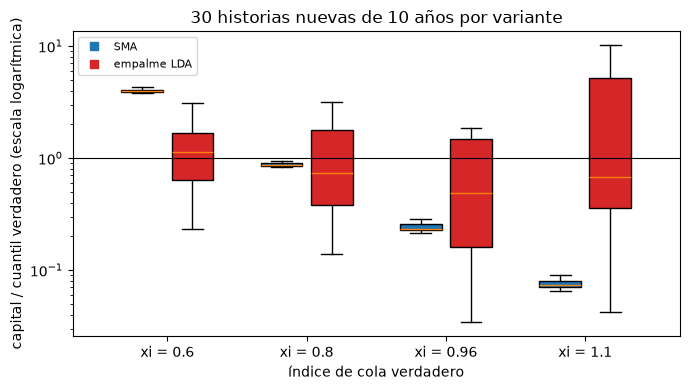

In [12]:
# Dibujar los capitales nuevos sobre el cuantil verdadero, SMA y empalme LDA, un par de cajas por variante
fig, ax = plt.subplots(figsize=(7.0, 4.0))
colors = {"orc": "tab:blue", "lda_splice": "tab:red"}
for k, (name, doc) in enumerate(docs.items()):
    truth_q = doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
    for offset, rung in ((-0.18, "orc"), (0.18, "lda_splice")):
        ratios = fresh[name][rung][np.isfinite(fresh[name][rung])] / truth_q
        box = ax.boxplot(ratios, positions=[k + offset], widths=0.3, patch_artist=True, showfliers=False)
        box["boxes"][0].set_facecolor(colors[rung])
ax.set_yscale("log")
ax.axhline(1.0, color="black", linewidth=0.8)
ax.set_xticks(range(4))
ax.set_xticklabels(["xi = %s" % doc["outputs"]["tail_index"] for doc in docs.values()])
ax.plot([], [], "s", color=colors["orc"], label="SMA")
ax.plot([], [], "s", color=colors["lda_splice"], label="empalme LDA")
ax.set_xlabel("índice de cola verdadero")
ax.set_ylabel("capital / cuantil verdadero (escala logarítmica)")
ax.set_title("30 historias nuevas de 10 años por variante")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Las cajas repiten el hallazgo versionado sobre historias nuevas. La caja de la SMA es una franja delgada, con un rango intercuartil de 0,159 a 0,009 de la verdad, pero queda en 3,986 veces la verdad con índice de cola 0,6 y en 0,073 con 1,1: estable, y equivocada en direcciones opuestas. Las cajas del empalme LDA son altas, de 1,024 a 4,840 de rango intercuartil, y el empalme pudo ajustarse en solo 25, 26, 18 y 15 de las 30 historias, de modo que donde existe es poco confiable y a menudo no existe, como mostró la tabla de una historia con sus entradas no definidas. La prueba del motor pinta de rojo todas las cajas salvo la SMA en 0,8. Treinta historias muestran el patrón, no su tamaño.

Las dos últimas celdas vuelven a los números versionados, 1.000 historias por celda, para someter las dos afirmaciones de la literatura a un tamaño que ninguna corrida de 30 historias alcanza: la SMA sigue poco el riesgo, y el capital LDA es inestable.

In [13]:
# Poner dos afirmaciones de la literatura frente a los números versionados de la celda de 10 años y umbral de EUR 20.000
spread_truth, spread_sma, spread_lda, spread_lda_iqr = [], [], [], []
for name, doc in docs.items():
    cell = next(c for c in doc["outputs"]["cells"] if c["id"] == "y10-h20000")
    spread_truth.append(doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"])
    spread_sma.append(cell["sma"]["orc_eur"]["median"])
    spread_lda.append(cell["capital"]["lda_splice"]["ratio_to_truth"]["median"])
    spread_lda_iqr.append(cell["capital"]["lda_splice"]["iqr_over_truth"])
print(
    "insensibilidad al riesgo: el SMA se mueve en un factor %.2f mientras el cuantil verdadero se mueve en %.1f" % (
        max(spread_sma) / min(spread_sma), max(spread_truth) / min(spread_truth)
    )
)
print("inestabilidad: el rango intercuartil del empalme LDA sobre la verdad es %s" % np.round(spread_lda_iqr, 2))
print(
    "SMA / verdad por variante:", np.round(np.array(spread_sma) / np.array(spread_truth), 3),
    "| mediana empalme LDA / verdad:", np.round(spread_lda, 3)
)

insensibilidad al riesgo: el SMA se mueve en un factor 1.22 mientras el cuantil verdadero se mueve en 63.4
inestabilidad: el rango intercuartil del empalme LDA sobre la verdad es [1.35 1.98 2.23 2.32]
SMA / verdad por variante: [3.975 0.869 0.239 0.077] | mediana empalme LDA / verdad: [0.84  0.909 0.929 0.725]


La siguiente celda dibuja la razón de cada capital al cuantil verdadero, con la banda de 25% a 75% del empalme LDA sobre 1.000 historias, para los cuatro índices de cola. Una razón de 1 es un capital igual a la verdad.

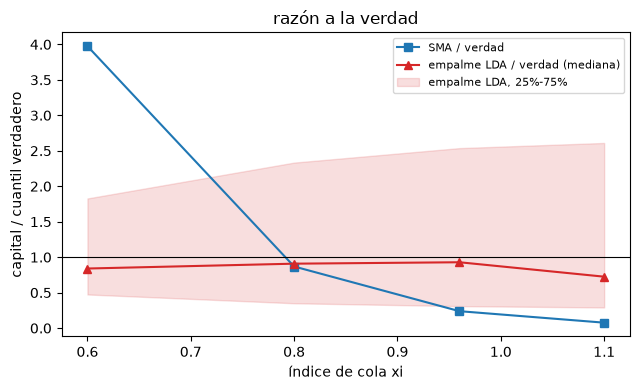

In [14]:
# Dibujar la razón de la SMA y del empalme LDA al cuantil verdadero, con la banda intercuartil del empalme
cells = {name: next(c for c in doc["outputs"]["cells"] if c["id"] == "y10-h20000") for name, doc in docs.items()}
truths = np.array([doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"] for doc in docs.values()])
splice = {
    key: np.array(
        [cells[n]["capital"]["lda_splice"]["capital_eur"][key] for n in docs]
    ) for key in ("p25", "median", "p75")
}
sma_median = np.array([cells[n]["sma"]["orc_eur"]["median"] for n in docs])
fig, ax = plt.subplots(figsize=(6.5, 4.0))
ax.plot(xis, sma_median / truths, "s-", color="tab:blue", label="SMA / verdad")
ax.plot(xis, splice["median"] / truths, "^-", color="tab:red", label="empalme LDA / verdad (mediana)")
ax.fill_between(
    xis, splice["p25"] / truths, splice["p75"] / truths, color="tab:red", alpha=0.15, label="empalme LDA, 25%-75%"
)
ax.axhline(1.0, color="black", linewidth=0.8)
ax.set_xlabel("índice de cola xi")
ax.set_ylabel("capital / cuantil verdadero")
ax.set_title("razón a la verdad")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La línea azul de la SMA baja de 3,975 veces la verdad con índice de cola 0,6 a 0,077 con 1,1: cobra de más a un banco de cola liviana y de menos a uno de cola pesada, por construcción, porque nunca mira la cola. La mediana roja queda cerca de 1, entre 0,84 y 0,93 veces la verdad y 0,725 al final, pero su banda sombreada es tan ancha como la propia verdad, con un rango intercuartil de 1,35, 1,98, 2,23 y 2,32. Ningún estimador es bueno: uno es preciso y equivocado, el otro acierta en promedio y es poco confiable para un banco concreto. La figura es una medición sobre un generador, no un veredicto sobre la decisión del Comité.

### Los peldaños de severidad robusta

La inestabilidad de arriba viene del ajuste de la severidad: una GPD por máxima verosimilitud reacciona a cada pérdida grande, y
una más o una menos en diez años mueve el cuantil 99,9 % en un factor. Opdyke y Cavallo (2012) propusieron estimadores robustos para
la severidad de las pérdidas operacionales, el estimador óptimamente robusto al sesgo de Hampel, Ronchetti, Rousseeuw y Stahel
(1986, sección 4.2), que acota la influencia que puede tener cualquier pérdida individual, y la distancia mínima de Cramér-von
Mises, que ajusta la función de distribución completa en lugar de la verosimilitud de cada punto, junto a la aproximación de una
pérdida corregida por la media. El módulo `riskvalidation.oprisk.robust` del motor implementa los tres, y la escalera C17 del
producto los lleva como cuatro peldaños: la GPD por máxima verosimilitud, por Cramér-von Mises y por el estimador óptimamente
robusto al sesgo con eficiencia de 95 %, cada uno con la SLA ajustada por la media, y una lognormal por Cramér-von Mises como
control mal especificado. La forma ajustada por la media es la que enuncia Degen (2010) y repite arXiv 1607.02319; el texto primario
de Opdyke y Cavallo no se leyó, así que los peldaños llevan el estado `SECONDARY_SOURCE`.

Las historias nuevas de la celda de arriba ya corrieron todos los peldaños, porque `replicate.estimate` los devuelve todos; la celda
siguiente lee los tres peldaños GPD junto al LDA con empalme, como capital sobre el cuantil verdadero de cada variante.

In [ ]:
# Los peldaños robustos junto al LDA con empalme sobre las mismas 30 historias nuevas: definidos, mediana y rango
ROBUST = ("lda_splice", "sla_mean_adjusted", "sla_cvm", "sla_obre")
quartiles = {}
defined_label = "definidos"
for name, doc in docs.items():
    truth_q = doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
    for rung in ROBUST:
        ratios = fresh[name][rung][np.isfinite(fresh[name][rung])] / truth_q
        quartiles[(name, rung)] = np.percentile(ratios, [25, 50, 75])
        q25, q50, q75 = quartiles[(name, rung)]
        print(f"{name:8s} {rung:18s} {defined_label} {ratios.size:2d} | median {q50:6.3f} | IQR {q75 - q25:6.3f}")


Un peldaño que rechaza una historia no se dibuja: la SLA necesita una media finita, así que cuando el índice de cola
ajustado llega a 1 el peldaño no devuelve nada, y por eso los conteos definidos caen en el índice de cola 1,1 a entre 10 y 13 de 30
contra 15 del empalme. La figura dibuja cada mediana como un punto y su rango intercuartil como una barra, en escala logarítmica
donde la verdad es la línea negra.

In [ ]:
# Dibujar la mediana de capital / verdad de cada peldaño y variante, con su rango intercuartil como barra
fig, ax = plt.subplots(figsize=(9.0, 4.0))
offsets = np.linspace(-0.27, 0.27, len(ROBUST))
for offset, rung in zip(offsets, ROBUST):
    x = np.arange(len(docs)) + offset
    q = np.array([quartiles[(name, rung)] for name in docs])
    ax.vlines(x, q[:, 0], q[:, 2], linewidth=6, alpha=0.35)
    ax.plot(x, q[:, 1], "o", label=rung)
ax.set_yscale("log")
ax.axhline(1.0, color="black", linewidth=0.8)
ax.set_xticks(range(len(docs)))
ax.set_xticklabels(["xi = %s" % doc["outputs"]["tail_index"] for doc in docs.values()])
ax.set_xlabel("índice de cola verdadero")
ax.set_ylabel("capital / cuantil verdadero (escala log.)")
ax.set_title("Ajustes robustos de severidad frente al empalme, 30 historias nuevas por variante")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()


Con índice de cola 0,6 el empalme es el más ajustado (un rango intercuartil de 1,024 de la verdad) y los ajustes robustos
no ganan nada; la SLA ajustada por la media y el ajuste óptimamente robusto quedan más cerca de la verdad (1,056 y 1,069) pero se
dispersan más. En 0,8 y 0,96 el orden se invierte: el ajuste de Cramér-von Mises tiene una mediana de 0,862 y 0,555 con un rango de
1,065 y 0,369, el óptimamente robusto 0,832 y 0,899, mientras el empalme baja a 0,483 en 0,96 con un rango de 1,309. En 1,1, donde
la media es infinita, todos los peldaños SLA colapsan a cerca de un quinto de la verdad con un rango estrecho, una respuesta estable
y equivocada, y el empalme queda cerca de 0,67 con un rango de casi cinco veces la verdad. La robustez compra estrechez donde la cola
es pesada pero finita, y nada donde se rompe el supuesto de media finita del modelo.

## Resultados

**Respuesta:** Ninguna de las dos críticas queda refutada en este banco sintético. La SMA versionada se mueve en un factor de 1,22 mientras el cuantil de 99,9% verdadero se mueve en 63,4, y vale 3,975 veces la verdad con índice de cola 0,6 y 0,077 veces con 1,1; en 30 historias nuevas por variante es estable (dispersión de 0,159 a 0,009) pero con sesgo de +2,986 a -0,927. El empalme LDA sigue el riesgo en promedio, pero su rango intercuartil sobre la verdad es 1,35, 1,98, 2,23 y 2,32 en las historias versionadas y 4,840 en la cola más pesada en las nuevas, y el índice de cola ajustado cerca de 1 cruza la línea de media finita solo por muestreo.

- **Lado a lado.** En las 16 celdas, el SMA es angosto y el empalme LDA es ancho. El rango intercuartil del SMA sobre la verdad está entre 0,015 y 0,183, mientras el empalme tiene un rango entre 1,35 y 3,30 veces la verdad. El empalme está definido en 128 a 996 de las 1.000 historias, menos con índice de cola 1,1 y umbral de EUR 10.000 con 10 años.
- **Insensibilidad al riesgo.** Con 10 años y umbral de EUR 20.000 el cuantil de 99,9% verdadero crece en un factor de 63,4 entre los índices de cola 0,6 y 1,1 (de EUR 33,9 millones a EUR 2,15 mil millones), el empalme LDA mediano en 54,7, y el SMA mediano solo en 1,2 (de EUR 134,7 millones a EUR 165,0 millones). El SMA es 3,98 veces la verdad con índice de cola 0,6, 0,87 con 0,8, 0,24 con 0,96 y 0,077 con 1,1: sobrestima una cola liviana y subestima una pesada. El SMA no está calibrado al cuantil de 99,9% de ningún banco (el documento lo dice), así que estas razones son una comparación, no un error del SMA.
- **Inestabilidad.** El rango intercuartil del empalme sobre la verdad es 1,35, 1,98, 2,23 y 2,32 en los cuatro índices de cola: para un banco con diez años de datos, el capital LDA de dos bancos del mismo riesgo verdadero difiere casi tanto como el riesgo mismo. Las medianas están cerca de la verdad (0,84, 0,91, 0,93 y 0,73 veces ella), así que el LDA no se aleja en promedio y se aleja mucho en cualquier historia.
- **Cerca de 1.** En una sola historia regenerada el índice de cola ajustado en cuatro umbrales es 1,02, 0,96, 1,03 y 0,87 donde la verdad es 0,96, así que dos de cuatro estimaciones cruzan la línea de media finita, y 0,96, 0,95, 1,04 y 0,89 donde la verdad es 1,1, así que tres de cuatro estimaciones dicen que la media es finita cuando no lo es. Errores estándar de 0,10 a 0,33 lo explican.
- **Una historia.** El SMA de la historia única regenerada queda cerca de la mediana versionada en tres variantes (EUR 132,4 millones frente a 134,7 millones, EUR 143,2 millones frente a 142,0 millones, EUR 153,8 millones frente a 151,6 millones) y 13% bajo ella con índice de cola 1,1 (EUR 143,2 millones frente a 165,0 millones), donde unas pocas pérdidas grandes mueven el promedio de diez años.
- **Qué dice esto de bancos reales.** Nada directamente: el banco es sintético y el generador es la única verdad. Dice que las dos afirmaciones de la crítica, un SMA que sigue muy poco al riesgo y un LDA inestable con los largos de datos y los índices de cola que sugieren las estadísticas de Basilea, se cumplen para los estimadores y umbrales de este caso, y mide ambas con una verdad conocida.

Lo que este notebook no muestra: cómo depende la dispersión del capital LDA del largo de la historia y del índice de cola, medida con la prueba de estabilidad del motor sobre historias independientes (el notebook de nivel 4).

Los peldaños de severidad robusta estrechan el capital donde la cola es pesada pero de media finita: con índice de
cola 0,96 el ajuste de Cramér-von Mises tiene un rango intercuartil de 0,369 de la verdad contra 1,309 del empalme, mientras con 0,6
el empalme sigue siendo el más ajustado y con 1,1 todos los peldaños SLA colapsan a cerca de un quinto de la verdad.

## Resumen

- El Comité de Basilea eliminó el AMA por su complejidad y la falta de comparabilidad de los modelos internos, y lo reemplazó por el SMA no basado en modelos; los críticos argumentaron que el SMA es insensible al riesgo e inestable.
- En un banco sintético de verdad conocida, el SMA cambia en un factor de 1,2 mientras el cuantil verdadero cambia en 63, y es 3,98 veces la verdad con una cola liviana y 0,077 con una pesada.
- La mediana del empalme LDA está cerca de la verdad pero su rango intercuartil es de 1,35 a 2,32 veces la verdad con diez años de datos; el índice de cola ajustado cerca de 1 cruza la línea de media finita solo por muestreo.
- Son mediciones sobre un generador, no afirmaciones sobre bancos reales, y el argumento de la inestabilidad como razón de la decisión de Basilea es la lectura de la investigación, no la del Comité.

**Qué probar a continuación.** Abre el documento `xi-0-96.json` e imprime las celdas de 5 años frente a las de 10 años para ver crecer la dispersión del empalme. Luego sigue con el notebook 08, que mide esa dispersión con la prueba de estabilidad del motor.

- Los ajustes robustos de severidad estrechan el capital con índices de cola 0,8 y 0,96, no con 0,6, y dan un capital estable y equivocado cuando la media es infinita.

## Referencias

- BCBS (2016), Standardised Measurement Approach for operational risk, documento consultivo, 4 de marzo de 2016. https://www.bis.org/bcbs/publ/d355.htm
- BCBS (2017), Basel III: Finalising post-crisis reforms. https://www.bis.org/bcbs/publ/d424.htm
- BCBS, Basel Framework OPE25, Calculation of RWA for operational risk. https://www.bis.org/basel_framework/chapter/OPE/25.htm
- Peters, G. W., Shevchenko, P. V., Hassani, B. y Chapelle, A. (2016), Should the advanced measurement approach be replaced with the standardized measurement approach for operational risk?, Journal of Operational Risk 11(3). https://arxiv.org/abs/1607.02319
- Mignola, G., Ugoccioni, R. y Cope, E. (2016), Comments on the Basel Committee on Banking Supervision proposal for a new standardized approach for operational risk, Journal of Operational Risk 11(3), 51-69. https://doi.org/10.21314/JOP.2016.184
- Degen, M. (2010), The calculation of minimum regulatory capital using single-loss approximations, Journal of Operational Risk 5(4), 3-17. https://doi.org/10.21314/JOP.2010.084
- Chavez-Demoulin, V., Embrechts, P. y Neslehova, J. (2006), Quantitative models for operational risk: extremes, dependence and aggregation, Journal of Banking and Finance 30(10), 2635-2658. https://doi.org/10.1016/j.jbankfin.2005.11.008

- Opdyke, J. D. y Cavallo, A. (2012), Estimating operational risk capital: the challenges of truncation, the hazards of maximum likelihood estimation, and the promise of robust statistics, Journal of Operational Risk 7(3) (texto primario no leído; los estimadores siguen sus definiciones de manual)
- Hampel, F. R., Ronchetti, E. M., Rousseeuw, P. J. y Stahel, W. A. (1986), Robust Statistics: The Approach Based on Influence Functions, Wiley, sección 4.2.
- Degen, M. (2010), el término de segundo orden de la aproximación de una pérdida, tal como lo enuncia arXiv 1607.02319, https://arxiv.org/abs/1607.02319